# Multicolinealidad: ¿qué información aportan nuestros regresores?

*¿Qué ocurre cuando dos o más variables explicativas contienen información muy parecida?*

Utilizaremos datos de presión arterial para distinguir dos situaciones: cuando los coeficientes no pueden determinarse de manera única y cuando sí podemos estimarlos, pero su precisión puede verse afectada. Al final, utilizaremos `olsrr` para examinar el diagnóstico y discutiremos qué decisiones permite justificar.

## Importamos los datos

Trabajaremos con 20 pacientes. `BP` es la presión arterial; `Age`, la edad; `Weight`, el peso; `BSA`, la superficie corporal; `Dur`, la duración de la hipertensión; `Pulse`, el pulso; y `Stress`, una medida de estrés. `Pt` identifica a cada paciente y **no es un regresor**.

El archivo `bloodpress.csv` reproduce los datos utilizados en las diapositivas del capítulo. La ruta relativa sigue la convención de los notebooks anteriores.

In [1]:
library(readr)

datos <- read_csv("../data/bloodpress.csv", show_col_types = FALSE)
head(datos)

Pt,BP,Age,Weight,BSA,Dur,Pulse,Stress
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,105,47,85.4,1.75,5.1,63,33
2,115,49,94.2,2.10,3.8,70,14
3,116,49,95.3,1.98,8.2,72,10
4,117,50,94.7,2.01,5.8,73,99
5,112,51,89.4,1.89,7.0,72,95
6,121,48,99.5,2.25,9.3,71,10


## Multicolinealidad perfecta: dos regresores con la misma información

Partimos del modelo:

$$
BP_i=\beta_1+\beta_2 Age_i+\beta_3 Weight_i+\beta_4 BSA_i
+\beta_5 Dur_i+\beta_6 Pulse_i+\beta_7 Stress_i+u_i.
$$

Para construir deliberadamente un caso de **multicolinealidad perfecta**, sustituimos el peso observado por $Weight_i=46\,BSA_i$. No alteramos la base original: creamos una copia.

In [2]:
datos_perfectos <- datos
datos_perfectos$Weight <- 46 * datos_perfectos$BSA

modelo_perfecto <- lm(BP ~ Age + Weight + BSA + Dur + Pulse + Stress,
                      data = datos_perfectos)

## ¿Por qué no podemos recuperar todos los coeficientes?

En el notebook 06 calculamos el estimador mediante $\mathbf b=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$. Esa fórmula requiere que $\mathbf X$ tenga **rango columna completo**.

Aquí la columna de `Weight` es 46 veces la de `BSA`. Comparamos el rango de $\mathbf X$ con su número de columnas y comprobamos qué ocurre al intentar invertir $\mathbf X^\top\mathbf X$.

In [3]:
x <- model.matrix(modelo_perfecto)
c(rango = qr(x)$rank, columnas = ncol(x))

try(solve(crossprod(x)), silent = TRUE)

rango columnas 
       6        7

## ¿Qué hace `lm()` cuando encuentra la dependencia exacta?

El problema no es que resulte imposible minimizar el $RSS$. Lo que no existe es una **solución única para todos los coeficientes**: distintas combinaciones pueden producir los mismos valores ajustados.

`lm()` detecta la dependencia y deja uno de los coeficientes sin estimar (aparece como `NA`).

In [4]:
coef(modelo_perfecto)
summary(modelo_perfecto)

(Intercept)         Age      Weight         BSA         Dur       Pulse 
 6.21215062  0.56296708  0.53377775          NA  0.07681788  0.45643686 
     Stress 
-0.01673366


Call:
lm(formula = BP ~ Age + Weight + BSA + Dur + Pulse + Stress, 
    data = datos_perfectos)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.3687 -0.9135  0.1546  0.9053  2.8020 

Coefficients: (1 not defined because of singularities)
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  6.21215    9.42927   0.659   0.5207    
Age          0.56297    0.20572   2.737   0.0161 *  
Weight       0.53378    0.07503   7.114 5.22e-06 ***
BSA               NA         NA      NA       NA    
Dur          0.07682    0.20437   0.376   0.7126    
Pulse        0.45644    0.15925   2.866   0.0124 *  
Stress      -0.01673    0.01303  -1.284   0.2199    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.718 on 14 degrees of freedom
Multiple R-squared:  0.9262,	Adjusted R-squared:  0.8998 
F-statistic: 35.14 on 5 and 14 DF,  p-value: 1.921e-07


## ¿Qué sí podemos estimar?

Estimamos dos especificaciones sobre los **mismos datos modificados**: una omite `BSA` y la otra omite `Weight`. Si $Weight=46\,BSA$, la contribución de ambos regresores es:

$$
\beta_3 Weight_i+\beta_4 BSA_i=(46\beta_3+\beta_4)BSA_i.
$$

Podemos estimar esta combinación, pero no identificar $\beta_3$ y $\beta_4$ por separado. Comparemos coeficientes, $RSS$ y valores ajustados.

In [5]:
sin_bsa <- lm(BP ~ Age + Weight + Dur + Pulse + Stress,
              data = datos_perfectos)
sin_weight <- lm(BP ~ Age + BSA + Dur + Pulse + Stress,
                 data = datos_perfectos)

c(b_Weight = coef(sin_bsa)["Weight"],
  b_BSA = coef(sin_weight)["BSA"],
  proporcion = coef(sin_weight)["BSA"] / coef(sin_bsa)["Weight"])

c(RSS_sin_BSA = deviance(sin_bsa),
  RSS_sin_Weight = deviance(sin_weight),
  maxima_diferencia_ajustados = max(abs(fitted(sin_bsa) - fitted(sin_weight))))

b_Weight.Weight       b_BSA.BSA  proporcion.BSA 
      0.5337778      24.5537765      46.0000000

RSS_sin_BSA              RSS_sin_Weight 
               4.132763e+01                4.132763e+01 
maxima_diferencia_ajustados 
               2.842171e-14

## Interpretación del caso perfecto

Los dos modelos producen prácticamente los mismos valores ajustados y el mismo $RSS$ (las diferencias numéricas, si aparecen, son de redondeo). Sus coeficientes de `Weight` y `BSA` no son iguales porque corresponden a unidades diferentes, pero guardan la proporción esperada de 46 a 1.

La multicolinealidad perfecta impide atribuir por separado a cada regresor una contribución que los datos no distinguen.

## Multicolinealidad imperfecta: recuperamos los datos originales

Ahora utilizamos el peso realmente observado. `Weight` y `BSA` están relacionados, pero no son múltiplos exactos. Una gráfica nos permite comparar ambos casos.

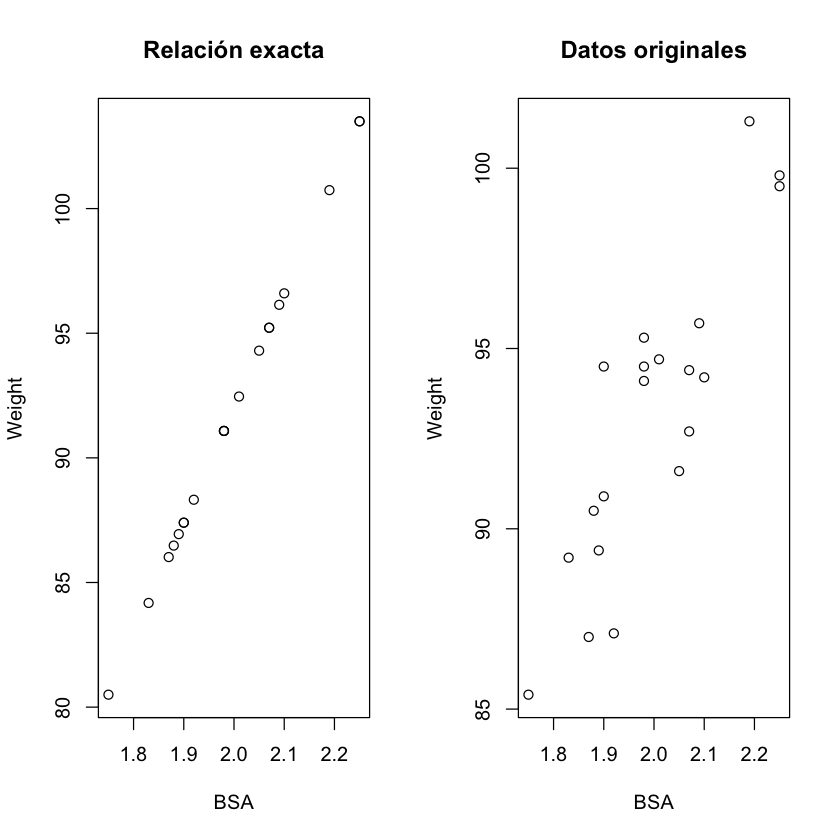

In [6]:
op <- par(mfrow = c(1, 2))
plot(datos_perfectos$BSA, datos_perfectos$Weight,
     xlab = "BSA", ylab = "Weight", main = "Relación exacta")
plot(datos$BSA, datos$Weight,
     xlab = "BSA", ylab = "Weight", main = "Datos originales")
par(op)

## Examinamos las correlaciones

La matriz de correlaciones ayuda a identificar asociaciones lineales entre pares de regresores. Sin embargo, la multicolinealidad también puede involucrar combinaciones de más de dos variables, por lo que esta matriz **no constituye un diagnóstico suficiente**.

In [7]:
regresores <- c("Age", "Weight", "BSA", "Dur", "Pulse", "Stress")
round(cor(datos[regresores]), 3)

,Age,Weight,BSA,Dur,Pulse,Stress
Age,1.000,0.407,0.378,0.344,0.619,0.368
Weight,0.407,1.000,0.875,0.201,0.659,0.034
BSA,0.378,0.875,1.000,0.131,0.465,0.018
Dur,0.344,0.201,0.131,1.000,0.402,0.312
Pulse,0.619,0.659,0.465,0.402,1.000,0.506
Stress,0.368,0.034,0.018,0.312,0.506,1.000


## Estimamos el modelo completo

Con los datos originales, la matriz de regresores tiene rango completo y podemos obtener todos los coeficientes mediante MCO. Recuperamos también sus errores estándar para relacionar la multicolinealidad con la inferencia.

In [8]:
mco <- lm(BP ~ Age + Weight + BSA + Dur + Pulse + Stress,
          data = datos)

summary(mco)


Call:
lm(formula = BP ~ Age + Weight + BSA + Dur + Pulse + Stress, 
    data = datos)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.93213 -0.11314  0.03064  0.21834  0.48454 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept) -12.870476   2.556650  -5.034 0.000229 ***
Age           0.703259   0.049606  14.177 2.76e-09 ***
Weight        0.969920   0.063108  15.369 1.02e-09 ***
BSA           3.776491   1.580151   2.390 0.032694 *  
Dur           0.068383   0.048441   1.412 0.181534    
Pulse        -0.084485   0.051609  -1.637 0.125594    
Stress        0.005572   0.003412   1.633 0.126491    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.4072 on 13 degrees of freedom
Multiple R-squared:  0.9962,	Adjusted R-squared:  0.9944 
F-statistic: 560.6 on 6 and 13 DF,  p-value: 6.395e-15


## Construimos manualmente el factor de inflación de la varianza

Para `Weight`, estimamos una **regresión auxiliar** sobre los demás regresores:

$$
Weight_i=\gamma_1+\gamma_2 Age_i+\gamma_3 BSA_i
+\gamma_4 Dur_i+\gamma_5 Pulse_i+\gamma_6 Stress_i+v_i.
$$

Su coeficiente de determinación $R^2_{Weight}$ mide qué proporción de la variación de `Weight` explican linealmente los otros regresores. Definimos:

$$
VIF_{Weight}=\frac{1}{1-R^2_{Weight}}.
$$

In [9]:
aux_weight <- lm(Weight ~ Age + BSA + Dur + Pulse + Stress,
                 data = datos)
R2_weight <- summary(aux_weight)$r.squared
vif_weight <- 1 / (1 - R2_weight)

c(R2_auxiliar = R2_weight, VIF_Weight = vif_weight)

R2_auxiliar  VIF_Weight 
  0.8811933   8.4170350

## Del VIF a la precisión del coeficiente

Bajo los supuestos clásicos, la varianza del estimador de un coeficiente puede escribirse como:

$$
\operatorname{Var}(b_j)=\frac{\sigma^2}{S_{jj}}\frac{1}{1-R_j^2}
=\frac{\sigma^2}{S_{jj}}VIF_j,
\qquad S_{jj}=\sum_i(x_{ji}-\bar x_j)^2.
$$

Así, el VIF indica una *inflación relativa de la varianza*, manteniendo fijos $\sigma^2$ y $S_{jj}$. No determina por sí mismo la magnitud del error estándar. Calculamos la varianza estimada de `Weight` y verificamos el resultado con `vcov()`.

In [10]:
s2 <- deviance(mco) / df.residual(mco)
S_weight <- sum((datos$Weight - mean(datos$Weight))^2)
var_weight <- s2 / S_weight * vif_weight

c(varianza_manual = var_weight,
  varianza_vcov = vcov(mco)["Weight", "Weight"],
  error_estandar = sqrt(var_weight))

varianza_manual   varianza_vcov  error_estandar 
    0.003982677     0.003982677     0.063108457

## Diagnóstico con `olsrr`: tolerancia y VIF

Una vez entendido el cálculo manual, utilizamos `olsrr::ols_vif_tol()` para obtener la **tolerancia** $1-R_j^2$ y el VIF de todos los regresores. No hace falta repetir seis regresiones auxiliares a mano.

Si el paquete no está instalado, ejecútalo una sola vez en R con `install.packages("olsrr")`.

In [11]:
olsrr::ols_vif_tol(mco)

Variables,Tolerance,VIF
<chr>,<dbl>,<dbl>
Age,0.5672772,1.762807
Weight,0.1188067,8.417035
BSA,0.1876612,5.328751
Dur,0.8082053,1.237309
Pulse,0.2265737,4.413575
Stress,0.5450051,1.834845


## Diagnóstico conjunto: valores propios e índices de condición

La correlación por pares y los VIF no agotan el análisis. En clase normalizamos las columnas de la matriz $\mathbf X$, **incluida la constante y sin centrarlas**, y construimos $\mathbf C=(\mathbf X^*)^\top\mathbf X^*$.

Si sus valores propios son $\lambda_1\geq\cdots\geq\lambda_k>0$, definimos:

$$
K=\frac{\lambda_1}{\lambda_k},
\qquad IC_j=\sqrt{\frac{\lambda_1}{\lambda_j}}.
$$

`ols_eigen_cindex()` devuelve valores propios, índices de condición y proporciones de descomposición de la varianza. Una cifra alta es una señal para investigar, **no una prueba estadística ni una orden de eliminar regresores**.

In [12]:
condicion <- olsrr::ols_eigen_cindex(mco)
condicion

c(IC_maximo = max(condicion[["Condition Index"]]),
  K = max(condicion[["Condition Index"]])^2)

Eigenvalue,Condition Index,intercept,Age,Weight,BSA,Dur,Pulse,Stress
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
6.6557834364,1.000000,2.829002e-05,3.185304e-05,5.353339e-06,0.0000184614,1.637810e-03,1.436903e-05,0.002971683
0.2679168643,4.984247,1.541824e-04,1.161880e-04,2.952138e-05,0.0001045335,2.276683e-05,4.177942e-05,0.551209359
0.0714205610,9.653570,5.468766e-04,3.936606e-04,8.183402e-05,0.0003086128,9.284885e-01,1.676090e-04,0.052402652
0.0026552088,50.066848,1.026859e-01,8.896935e-02,5.217231e-03,0.1698020481,7.355544e-04,3.978465e-03,0.025392439
0.0011111079,77.396526,3.723169e-01,7.775017e-01,9.151948e-03,0.0112520965,2.593679e-02,5.009585e-03,0.039087947
0.0009488883,83.751396,2.899528e-01,3.805511e-02,6.117022e-03,0.0735561383,4.316381e-02,4.375828e-01,0.143347158
0.0001639333,201.495821,2.343150e-01,9.493217e-02,9.793971e-01,0.7449581094,1.472197e-05,5.532054e-01,0.185588762


IC_maximo          K 
  201.4958 40600.5659

## ¿Qué indican los diagnósticos?

En esta muestra, el $VIF$ de `Weight` es aproximadamente **8.417** y el índice máximo de condición es aproximadamente **201.496**. Estos resultados merecen atención, aunque responden preguntas diferentes:

- El VIF cuantifica la inflación *relativa* de la varianza de cada pendiente.
- El índice de condición identifica direcciones de dependencia cercana dentro del conjunto de columnas de la matriz de regresores.
- Las proporciones de varianza que acompañan los índices permiten examinar qué coeficientes comparten esas direcciones.

La **multicolinealidad imperfecta**, por sí misma, no introduce sesgo ni invalida las pruebas $t$ y $F$ bajo los supuestos clásicos. Puede aumentar la incertidumbre de algunas estimaciones.

## ¿Debemos eliminar un regresor?

Para explorar la decisión, excluyamos `BSA` del modelo con datos originales. Comparamos el coeficiente y el error estándar de `Weight` antes y después de hacerlo.

La comparación es ilustrativa: **un error estándar menor no demuestra que el modelo reducido sea más adecuado**. Si la variable omitida pertenece a la especificación relevante y está asociada con el regresor conservado, omitirla puede introducir sesgo.

In [13]:
mco_sin_bsa <- lm(BP ~ Age + Weight + Dur + Pulse + Stress,
                  data = datos)

data.frame(
  Modelo = c("Completo", "Sin BSA"),
  b_Weight = c(coef(mco)["Weight"], coef(mco_sin_bsa)["Weight"]),
  Error_estandar = c(sqrt(vcov(mco)["Weight", "Weight"]),
                    sqrt(vcov(mco_sin_bsa)["Weight", "Weight"]))
)

Modelo,b_Weight,Error_estandar
<chr>,<dbl>,<dbl>
Completo,0.9699198,0.06310846
Sin BSA,1.0989583,0.03777346


## Interpretación de la evidencia

En este ejemplo, eliminar `BSA` reduce el error estándar estimado de `Weight`, pero también cambia su pendiente estimada. Por tanto, no basta con comparar VIF, valores $p$ o errores estándar para elegir entre especificaciones. Debemos preguntarnos *qué relación queremos estimar*, qué variables exige esa pregunta y cuánta información independiente ofrecen los datos.

La multicolinealidad perfecta limita la identificación individual de coeficientes. La imperfecta plantea principalmente un problema potencial de precisión. En ninguno de los dos casos el software puede sustituir la decisión econométrica.

## Para reflexionar

1. ¿Por qué los modelos que omiten alternativamente `Weight` y `BSA` ofrecen el mismo ajuste cuando imponemos $Weight=46\,BSA$, aun cuando sus coeficientes son distintos?
2. ¿Por qué un VIF relativamente alto no implica necesariamente un error estándar más grande que el de otro coeficiente?
3. ¿Qué diferencia hay entre el diagnóstico del VIF y el diagnóstico mediante índices de condición?
4. Si el error estándar de `Weight` disminuye al omitir `BSA`, ¿qué información adicional necesitarías para defender esa decisión?

## Documentación

- [Regresión lineal con `lm()`](https://stat.ethz.ch/R-manual/R-patched/library/stats/html/lm.html).
- [Diagnósticos de multicolinealidad en `olsrr`](https://cran.r-project.org/web/packages/olsrr/refman/olsrr.html): `ols_vif_tol()`, `ols_eigen_cindex()` y `ols_coll_diag()`.

*Datos del ejemplo de presión arterial: material del capítulo 04 de Econometría I.*